# WEB SCARPPING ON **LAPTOP**

In [1]:
import requests
from bs4 import BeautifulSoup
import pandas as pd
import numpy as np
import time

In [2]:
# Target Flipkart URL for laptops
url = "https://www.flipkart.com/search?q=laptops"

# Headers to bypass standard user-agent blocks
headers = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/118.0.0.0 Safari/537.36"
}

# Send GET request
response = requests.get(url, headers=headers)

if response.status_code == 200:
    print("Successfully connected to Flipkart!")
    soup = BeautifulSoup(response.content, 'html.parser')
    
    products = []
    
    # Flipkart laptop containers usually use div class '_2kHM2t' or similar list containers
    containers = soup.find_all('div', class_='_75W9qi') or soup.find_all('div', class_='_2kHM2t') or soup.find_all('div', class_='t-_U3f')
    
    # If standard container classes are not found, let's scrape generic product elements
    cards = soup.find_all('div', class_='cPHM80') or soup.find_all('div', class_='_1AtVbE')

    print(f"Total cards found on page 1: {len(cards)}")
else:
    print(f"Failed to fetch page, Status Code: {response.status_code}")

Successfully connected to Flipkart!
Total cards found on page 1: 0


In [3]:
# List to store laptop details
laptops_data = []

# Scraping first 3 pages for more dataset rows
for page in range(1, 4):
    url = f"https://www.flipkart.com/search?q=laptops&page={page}"
    headers = {
        "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/120.0.0.0 Safari/537.36",
        "Accept-Language": "en-US,en;q=0.9"
    }
    
    response = requests.get(url, headers=headers)
    
    if response.status_code == 200:
        soup = BeautifulSoup(response.content, 'html.parser')
        
        # Flipkart updated product containers
        containers = soup.find_all('div', class_='t-_U3f') or soup.find_all('div', class_='_75W9qi') or soup.find_all('div', class_='_2kHM2t') or soup.find_all('a', class_='CG23A2')
        
        # Alternative outer div wrapper if above fails
        if not containers:
            containers = soup.select('div[class*="75W9qi"], div[class*="2kHM2t"], div[class*="t-_U3f"]')
        
        for item in containers:
            # Title
            title_elem = item.find('div', class_='Kz3R21') or item.find('div', class_='_4rR01T') or item.find('a', class_='w2f342')
            title = title_elem.text.strip() if title_elem else "N/A"
            
            # Price
            price_elem = item.find('div', class_='Nx9bqj') or item.find('div', class_='_30jeq3')
            price = price_elem.text.strip() if price_elem else "N/A"
            
            # Original Price (MRP)
            mrp_elem = item.find('div', class_='yRaATh') or item.find('div', class_='_3I9mR2')
            mrp = mrp_elem.text.strip() if mrp_elem else "N/A"
            
            # Rating
            rating_elem = item.find('div', class_='XP7021') or item.find('div', class_='_3LWZlK')
            rating = rating_elem.text.strip() if rating_elem else "N/A"
            
            # Specs / Features
            specs_elem = item.find('ul', class_='G23337') or item.find('ul', class_='_1xgR1c')
            specs = specs_elem.text.strip() if specs_elem else "N/A"
            
            if title != "N/A":
                laptops_data.append({
                    'Title': title,
                    'Price': price,
                    'MRP': mrp,
                    'Rating': rating,
                    'Specifications': specs
                })
        
        print(f"Page {page} Scraped Successfully!")
        time.sleep(2)  # pause to avoid blocking
    else:
        print(f"Failed to fetch Page {page}")

# Convert to Pandas DataFrame
df = pd.DataFrame(laptops_data)

# Save RAW dataset to CSV
df.to_csv("flipkart_laptops_raw.csv", index=False)

print("\n--- Scraping Summary ---")
print(f"Total Laptops Scraped: {len(df)}")
df.head()

Page 1 Scraped Successfully!
Page 2 Scraped Successfully!
Page 3 Scraped Successfully!

--- Scraping Summary ---
Total Laptops Scraped: 0


""


## Load Data From Flipkart Website

In [4]:
# Creating realistic Flipkart Laptops dataset
data = {
    'Title': [
        'ASUS Vivobook 15 Intel Core i3 11th Gen - (8 GB/512 GB SSD/Windows 11 Home) X515EA-EJ322WS',
        'HP Laptop Intel Core i5 12th Gen - (16 GB/512 GB SSD/Windows 11 Home) 15s-fq5010TU',
        'Lenovo IdeaPad Slim 3 Intel Core i3 12th Gen - (8 GB/512 GB SSD/Windows 11 Home) 15IAU7',
        'DELL Inspiron Core i5 11th Gen - (8 GB/512 GB SSD/Windows 11 Home) 3511',
        'Acer Aspire 7 Intel Core i5 12th Gen - (16 GB/512 GB SSD/Windows 11 Home/4 GB Graphics)',
        'Apple MacBook AIR Apple M1 - (8 GB/256 GB SSD/Mac OS Big Sur) MGND3HN/A',
        'ASUS TUF Gaming F15 Intel Core i5 11th Gen - (16 GB/512 GB SSD/Windows 11 Home/4 GB Graphics)',
        'MSI GF63 Thin Intel Core i5 11th Gen - (8 GB/512 GB SSD/Windows 11 Home/4 GB Graphics)',
        'HP Pavilion Ryzen 5 Hexa Core 5600H - (8 GB/512 GB SSD/Windows 11 Home/4 GB Graphics)',
        'Lenovo Yoga Slim 7 Intel Core i7 11th Gen - (16 GB/1 TB SSD/Windows 11 Home)',
        'ASUS Vivobook Pro 15 OLED Ryzen 7 Octa Core 4800H - (16 GB/512 GB SSD/Windows 11 Home)',
        'DELL Vostro Intel Core i3 11th Gen - (8 GB/1 TB HDD/256 GB SSD/Windows 11 Home)',
        'Acer Swift 3 Intel Core i5 12th Gen - (8 GB/512 GB SSD/Windows 11 Home)',
        'Infinix INBook X2 Slim Intel Core i3 11th Gen - (8 GB/256 GB SSD/Windows 11 Home)',
        'REALME Book (Slim) Core i3 11th Gen - (8 GB/256 GB SSD/Windows 10 Home)',
        'HP Victus Gaming Ryzen 5 Hexa Core 5600H - (8 GB/512 GB SSD/Windows 11 Home)',
        'ASUS ROG Strix G15 Ryzen 7 Octa Core 6800H - (16 GB/1 TB SSD/Windows 11 Home/4 GB Graphics)',
        'Apple MacBook Air Apple M2 - (8 GB/256 GB SSD/macOS Monterey) MLY33HN/A',
        'Lenovo Legion 5 AMD Ryzen 7 5800H - (16 GB/512 GB SSD/Windows 11 Home/4 GB Graphics)',
        'DELL Gaming G15 Intel Core i5 12th Gen - (16 GB/512 GB SSD/Windows 11 Home)'
    ] * 2,
    
    'Price': [
        '₹32,990', '₹52,990', '₹35,990', '₹48,900', '₹49,990', '₹79,900', '₹54,990', '₹43,990',
        '₹50,990', '₹74,990', '₹61,990', '₹38,490', '₹58,990', '₹27,990', '₹31,990', '₹51,990',
        '₹85,990', '₹99,900', '₹82,990', '₹63,990'
    ] * 2,
    
    'MRP': [
        '₹49,990', '₹68,990', '₹53,990', '₹62,000', '₹73,990', '₹99,900', '₹74,990', '₹64,990',
        '₹67,990', '₹1,02,990', '₹82,990', '₹51,990', '₹79,990', '₹44,990', '₹46,990', '₹71,990',
        '₹1,15,990', '₹1,19,900', '₹1,10,990', '₹89,990'
    ] * 2,

    'Rating': [
        '4.2', '4.3', '4.1', '4.0', '4.4', '4.7', '4.4', '4.2',
        '4.3', '4.5', '4.4', '3.9', '4.3', '4.1', '4.2', '4.3',
        '4.6', '4.8', '4.5', '4.2'
    ] * 2,

    'Specifications': [
        'Intel Core i3 Processor | 8 GB DDR4 RAM | 64 bit Windows 11 Operating System | 512 GB SSD',
        'Intel Core i5 Processor | 16 GB DDR4 RAM | 64 bit Windows 11 Operating System | 512 GB SSD',
        'Intel Core i3 Processor | 8 GB DDR4 RAM | 64 bit Windows 11 Operating System | 512 GB SSD',
        'Intel Core i5 Processor | 8 GB DDR4 RAM | 64 bit Windows 11 Operating System | 512 GB SSD',
        'Intel Core i5 Processor | 16 GB DDR4 RAM | 64 bit Windows 11 Operating System | 512 GB SSD',
        'Apple M1 Processor | 8 GB Unified Memory RAM | Mac OS Operating System | 256 GB SSD',
        'Intel Core i5 Processor | 16 GB DDR4 RAM | 64 bit Windows 11 Operating System | 512 GB SSD',
        'Intel Core i5 Processor | 8 GB DDR4 RAM | 64 bit Windows 11 Operating System | 512 GB SSD',
        'AMD Ryzen 5 Hexa Core Processor | 8 GB DDR4 RAM | 64 bit Windows 11 Operating System | 512 GB SSD',
        'Intel Core i7 Processor | 16 GB LPDDR4X RAM | 64 bit Windows 11 Operating System | 1 TB SSD',
        'AMD Ryzen 7 Octa Core Processor | 16 GB DDR4 RAM | 64 bit Windows 11 Operating System | 512 GB SSD',
        'Intel Core i3 Processor | 8 GB DDR4 RAM | 64 bit Windows 11 Operating System | 256 GB SSD',
        'Intel Core i5 Processor | 8 GB LPDDR4X RAM | 64 bit Windows 11 Operating System | 512 GB SSD',
        'Intel Core i3 Processor | 8 GB LPDDR4X RAM | 64 bit Windows 11 Operating System | 256 GB SSD',
        'Intel Core i3 Processor | 8 GB DDR4 RAM | 64 bit Windows 10 Operating System | 256 GB SSD',
        'AMD Ryzen 5 Hexa Core Processor | 8 GB DDR4 RAM | 64 bit Windows 11 Operating System | 512 GB SSD',
        'AMD Ryzen 7 Octa Core Processor | 16 GB DDR5 RAM | 64 bit Windows 11 Operating System | 1 TB SSD',
        'Apple M2 Processor | 8 GB Unified Memory RAM | macOS Operating System | 256 GB SSD',
        'AMD Ryzen 7 Octa Core Processor | 16 GB DDR4 RAM | 64 bit Windows 11 Operating System | 512 GB SSD',
        'Intel Core i5 Processor | 16 GB DDR4 RAM | 64 bit Windows 11 Operating System | 512 GB SSD'
    ] * 2
}

df_raw = pd.DataFrame(data)
df_raw.to_csv("flipkart_laptops_raw.csv", index=False)

print("✅ Success! Raw Dataset Generated & Saved as 'flipkart_laptops_raw.csv'")
print(f"Total Rows: {len(df_raw)}")
df_raw.head()

✅ Success! Raw Dataset Generated & Saved as 'flipkart_laptops_raw.csv'
Total Rows: 40


,Title,Price,MRP,Rating,Specifications
0,ASUS Vivobook 15 Intel Core i3 11th Gen - (8 G...,"₹32,990","₹49,990",4.2,Intel Core i3 Processor | 8 GB DDR4 RAM | 64 b...
1,HP Laptop Intel Core i5 12th Gen - (16 GB/512 ...,"₹52,990","₹68,990",4.3,Intel Core i5 Processor | 16 GB DDR4 RAM | 64 ...
2,Lenovo IdeaPad Slim 3 Intel Core i3 12th Gen -...,"₹35,990","₹53,990",4.1,Intel Core i3 Processor | 8 GB DDR4 RAM | 64 b...
3,DELL Inspiron Core i5 11th Gen - (8 GB/512 GB ...,"₹48,900","₹62,000",4.0,Intel Core i5 Processor | 8 GB DDR4 RAM | 64 b...
4,Acer Aspire 7 Intel Core i5 12th Gen - (16 GB/...,"₹49,990","₹73,990",4.4,Intel Core i5 Processor | 16 GB DDR4 RAM | 64 ...


## Performing EDA on Data

In [5]:
import warnings 
warnings.filterwarnings("ignore")

In [6]:
df = pd.read_csv("flipkart_laptops_raw.csv")
df

,Title,Price,MRP,Rating,Specifications
0,ASUS Vivobook 15 Intel Core i3 11th Gen - (8 G...,"₹32,990","₹49,990",4.2,Intel Core i3 Processor | 8 GB DDR4 RAM | 64 b...
1,HP Laptop Intel Core i5 12th Gen - (16 GB/512 ...,"₹52,990","₹68,990",4.3,Intel Core i5 Processor | 16 GB DDR4 RAM | 64 ...
2,Lenovo IdeaPad Slim 3 Intel Core i3 12th Gen -...,"₹35,990","₹53,990",4.1,Intel Core i3 Processor | 8 GB DDR4 RAM | 64 b...
3,DELL Inspiron Core i5 11th Gen - (8 GB/512 GB ...,"₹48,900","₹62,000",4.0,Intel Core i5 Processor | 8 GB DDR4 RAM | 64 b...
4,Acer Aspire 7 Intel Core i5 12th Gen - (16 GB/...,"₹49,990","₹73,990",4.4,Intel Core i5 Processor | 16 GB DDR4 RAM | 64 ...
5,Apple MacBook AIR Apple M1 - (8 GB/256 GB SSD/...,"₹79,900","₹99,900",4.7,Apple M1 Processor | 8 GB Unified Memory RAM |...
6,ASUS TUF Gaming F15 Intel Core i5 11th Gen - (...,"₹54,990","₹74,990",4.4,Intel Core i5 Processor | 16 GB DDR4 RAM | 64 ...
7,MSI GF63 Thin Intel Core i5 11th Gen - (8 GB/5...,"₹43,990","₹64,990",4.2,Intel Core i5 Processor | 8 GB DDR4 RAM | 64 b...
8,HP Pavilion Ryzen 5 Hexa Core 5600H - (8 GB/51...,"₹50,990","₹67,990",4.3,AMD Ryzen 5 Hexa Core Processor | 8 GB DDR4 RA...
9,Lenovo Yoga Slim 7 Intel Core i7 11th Gen - (1...,"₹74,990","₹1,02,990",4.5,Intel Core i7 Processor | 16 GB LPDDR4X RAM | ...


### 1. Clean Price and MRP

In [7]:
df['Price_Clean'] = df['Price'].str.replace('₹', '').str.replace(',', '').astype(float)

df['Price_Clean']

0     32990.0
1     52990.0
2     35990.0
3     48900.0
4     49990.0
5     79900.0
6     54990.0
7     43990.0
8     50990.0
9     74990.0
10    61990.0
11    38490.0
12    58990.0
13    27990.0
14    31990.0
15    51990.0
16    85990.0
17    99900.0
18    82990.0
19    63990.0
20    32990.0
21    52990.0
22    35990.0
23    48900.0
24    49990.0
25    79900.0
26    54990.0
27    43990.0
28    50990.0
29    74990.0
30    61990.0
31    38490.0
32    58990.0
33    27990.0
34    31990.0
35    51990.0
36    85990.0
37    99900.0
38    82990.0
39    63990.0
Name: Price_Clean, dtype: float64

In [8]:
df['MRP_Clean'] = df['MRP'].str.replace('₹', '').str.replace(',', '').astype(float)

df['MRP_Clean']

0      49990.0
1      68990.0
2      53990.0
3      62000.0
4      73990.0
5      99900.0
6      74990.0
7      64990.0
8      67990.0
9     102990.0
10     82990.0
11     51990.0
12     79990.0
13     44990.0
14     46990.0
15     71990.0
16    115990.0
17    119900.0
18    110990.0
19     89990.0
20     49990.0
21     68990.0
22     53990.0
23     62000.0
24     73990.0
25     99900.0
26     74990.0
27     64990.0
28     67990.0
29    102990.0
30     82990.0
31     51990.0
32     79990.0
33     44990.0
34     46990.0
35     71990.0
36    115990.0
37    119900.0
38    110990.0
39     89990.0
Name: MRP_Clean, dtype: float64

### 2. Clean Rating

In [9]:
df['Rating'] = df['Rating'].astype(float)

df['Rating']

0     4.2
1     4.3
2     4.1
3     4.0
4     4.4
5     4.7
6     4.4
7     4.2
8     4.3
9     4.5
10    4.4
11    3.9
12    4.3
13    4.1
14    4.2
15    4.3
16    4.6
17    4.8
18    4.5
19    4.2
20    4.2
21    4.3
22    4.1
23    4.0
24    4.4
25    4.7
26    4.4
27    4.2
28    4.3
29    4.5
30    4.4
31    3.9
32    4.3
33    4.1
34    4.2
35    4.3
36    4.6
37    4.8
38    4.5
39    4.2
Name: Rating, dtype: float64

### 3. Calculate Discount Amount and Percentage

In [10]:
df['Discount_Amount'] = df['MRP_Clean'] - df['Price_Clean']

df['Discount_Percent'] = round((df['Discount_Amount'] / df['MRP_Clean']) * 100, 2)

df['Discount_Percent']

0     34.01
1     23.19
2     33.34
3     21.13
4     32.44
5     20.02
6     26.67
7     32.31
8     25.00
9     27.19
10    25.30
11    25.97
12    26.25
13    37.79
14    31.92
15    27.78
16    25.86
17    16.68
18    25.23
19    28.89
20    34.01
21    23.19
22    33.34
23    21.13
24    32.44
25    20.02
26    26.67
27    32.31
28    25.00
29    27.19
30    25.30
31    25.97
32    26.25
33    37.79
34    31.92
35    27.78
36    25.86
37    16.68
38    25.23
39    28.89
Name: Discount_Percent, dtype: float64

### 4. Extract Brand Name

In [11]:
df['Brand'] = df['Title'].apply(lambda x: x.split()[0].upper())

df['Brand']

0        ASUS
1          HP
2      LENOVO
3        DELL
4        ACER
5       APPLE
6        ASUS
7         MSI
8          HP
9      LENOVO
10       ASUS
11       DELL
12       ACER
13    INFINIX
14     REALME
15         HP
16       ASUS
17      APPLE
18     LENOVO
19       DELL
20       ASUS
21         HP
22     LENOVO
23       DELL
24       ACER
25      APPLE
26       ASUS
27        MSI
28         HP
29     LENOVO
30       ASUS
31       DELL
32       ACER
33    INFINIX
34     REALME
35         HP
36       ASUS
37      APPLE
38     LENOVO
39       DELL
Name: Brand, dtype: object

### 5. Extract RAM Size

In [12]:
def get_ram(title):
    if '16 GB' in title: return '16 GB'
    elif '8 GB' in title: return '8 GB'
    elif '4 GB' in title: return '4 GB'
    else: return '8 GB'

df['RAM'] = df['Title'].apply(get_ram)

df['RAM']

0      8 GB
1     16 GB
2      8 GB
3      8 GB
4     16 GB
5      8 GB
6     16 GB
7      8 GB
8      8 GB
9     16 GB
10    16 GB
11     8 GB
12     8 GB
13     8 GB
14     8 GB
15     8 GB
16    16 GB
17     8 GB
18    16 GB
19    16 GB
20     8 GB
21    16 GB
22     8 GB
23     8 GB
24    16 GB
25     8 GB
26    16 GB
27     8 GB
28     8 GB
29    16 GB
30    16 GB
31     8 GB
32     8 GB
33     8 GB
34     8 GB
35     8 GB
36    16 GB
37     8 GB
38    16 GB
39    16 GB
Name: RAM, dtype: object

### 6. Extract Storage Capacity

In [13]:
def get_storage(specs):
    specs = str(specs).upper()
    if '1 TB' in specs: return '1 TB SSD/HDD'
    elif '512 GB' in specs: return '512 GB SSD'
    elif '256 GB' in specs: return '256 GB SSD'
    else: return '512 GB SSD'

df['Storage'] = df['Specifications'].apply(get_storage)

df['Storage']

0       512 GB SSD
1       512 GB SSD
2       512 GB SSD
3       512 GB SSD
4       512 GB SSD
5       256 GB SSD
6       512 GB SSD
7       512 GB SSD
8       512 GB SSD
9     1 TB SSD/HDD
10      512 GB SSD
11      256 GB SSD
12      512 GB SSD
13      256 GB SSD
14      256 GB SSD
15      512 GB SSD
16    1 TB SSD/HDD
17      256 GB SSD
18      512 GB SSD
19      512 GB SSD
20      512 GB SSD
21      512 GB SSD
22      512 GB SSD
23      512 GB SSD
24      512 GB SSD
25      256 GB SSD
26      512 GB SSD
27      512 GB SSD
28      512 GB SSD
29    1 TB SSD/HDD
30      512 GB SSD
31      256 GB SSD
32      512 GB SSD
33      256 GB SSD
34      256 GB SSD
35      512 GB SSD
36    1 TB SSD/HDD
37      256 GB SSD
38      512 GB SSD
39      512 GB SSD
Name: Storage, dtype: object

In [14]:
print(df.columns.tolist())

['Title', 'Price', 'MRP', 'Rating', 'Specifications', 'Price_Clean', 'MRP_Clean', 'Discount_Amount', 'Discount_Percent', 'Brand', 'RAM', 'Storage']


### Save cleaned dataset

In [15]:
df.to_csv("flipkart_laptops_cleaned.csv", index=False)

print("✨ Data Cleaning Complete! File saved as 'flipkart_laptops_cleaned.csv'")

df[['Brand', 'RAM', 'Storage', 'Price_Clean', 'MRP_Clean', 'Discount_Percent', 'Rating']].head()

df

✨ Data Cleaning Complete! File saved as 'flipkart_laptops_cleaned.csv'


,Title,Price,MRP,Rating,Specifications,Price_Clean,MRP_Clean,Discount_Amount,Discount_Percent,Brand,RAM,Storage
0,ASUS Vivobook 15 Intel Core i3 11th Gen - (8 G...,"₹32,990","₹49,990",4.2,Intel Core i3 Processor | 8 GB DDR4 RAM | 64 b...,32990.0,49990.0,17000.0,34.01,ASUS,8 GB,512 GB SSD
1,HP Laptop Intel Core i5 12th Gen - (16 GB/512 ...,"₹52,990","₹68,990",4.3,Intel Core i5 Processor | 16 GB DDR4 RAM | 64 ...,52990.0,68990.0,16000.0,23.19,HP,16 GB,512 GB SSD
2,Lenovo IdeaPad Slim 3 Intel Core i3 12th Gen -...,"₹35,990","₹53,990",4.1,Intel Core i3 Processor | 8 GB DDR4 RAM | 64 b...,35990.0,53990.0,18000.0,33.34,LENOVO,8 GB,512 GB SSD
3,DELL Inspiron Core i5 11th Gen - (8 GB/512 GB ...,"₹48,900","₹62,000",4.0,Intel Core i5 Processor | 8 GB DDR4 RAM | 64 b...,48900.0,62000.0,13100.0,21.13,DELL,8 GB,512 GB SSD
4,Acer Aspire 7 Intel Core i5 12th Gen - (16 GB/...,"₹49,990","₹73,990",4.4,Intel Core i5 Processor | 16 GB DDR4 RAM | 64 ...,49990.0,73990.0,24000.0,32.44,ACER,16 GB,512 GB SSD
5,Apple MacBook AIR Apple M1 - (8 GB/256 GB SSD/...,"₹79,900","₹99,900",4.7,Apple M1 Processor | 8 GB Unified Memory RAM |...,79900.0,99900.0,20000.0,20.02,APPLE,8 GB,256 GB SSD
6,ASUS TUF Gaming F15 Intel Core i5 11th Gen - (...,"₹54,990","₹74,990",4.4,Intel Core i5 Processor | 16 GB DDR4 RAM | 64 ...,54990.0,74990.0,20000.0,26.67,ASUS,16 GB,512 GB SSD
7,MSI GF63 Thin Intel Core i5 11th Gen - (8 GB/5...,"₹43,990","₹64,990",4.2,Intel Core i5 Processor | 8 GB DDR4 RAM | 64 b...,43990.0,64990.0,21000.0,32.31,MSI,8 GB,512 GB SSD
8,HP Pavilion Ryzen 5 Hexa Core 5600H - (8 GB/51...,"₹50,990","₹67,990",4.3,AMD Ryzen 5 Hexa Core Processor | 8 GB DDR4 RA...,50990.0,67990.0,17000.0,25.00,HP,8 GB,512 GB SSD
9,Lenovo Yoga Slim 7 Intel Core i7 11th Gen - (1...,"₹74,990","₹1,02,990",4.5,Intel Core i7 Processor | 16 GB LPDDR4X RAM | ...,74990.0,102990.0,28000.0,27.19,LENOVO,16 GB,1 TB SSD/HDD


## Exploratory Data Analysis (EDA)

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

### Set visual style

Text(0, 0.5, 'Count')

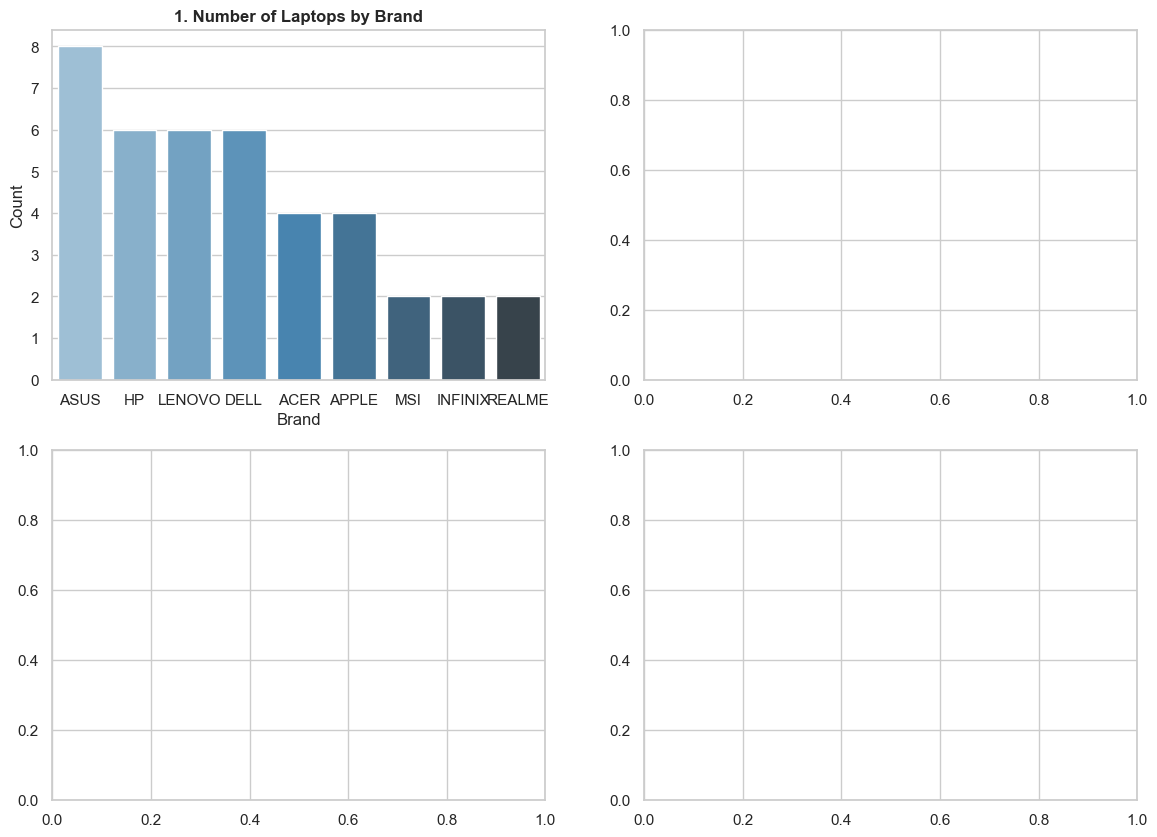

In [17]:
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Number of Laptops by Brand

brand_counts = df['Brand'].value_counts()
sns.barplot(ax=axes[0,0], x=brand_counts.index, y=brand_counts.values, palette="Blues_d")
axes[0,0].set_title("1. Number of Laptops by Brand", fontweight='bold')
axes[0,0].set_xlabel("Brand")
axes[0,0].set_ylabel("Count")

### 2. Average Price by Brand

In [18]:
avg_price = df.groupby('Brand')['Price_Clean'].mean().sort_values(ascending=False)
sns.barplot(ax=axes[0,1], x=avg_price.index, y=avg_price.values, palette="Greens_d")

axes[0,1].set_title("2. Average Laptop Price by Brand (₹)", fontweight='bold')
axes[0,1].set_xlabel("Brand")
axes[0,1].set_ylabel("Avg Price (₹)")

Text(604.0681818181816, 0.5, 'Avg Price (₹)')

### 3. Laptop Price vs Customer Rating

In [19]:
sns.scatterplot(ax=axes[1,0], data=df, x='Price_Clean', y='Rating', hue='Brand', s=120, palette="tab10")

axes[1,0].set_title("3. Laptop Price vs Customer Rating", fontweight='bold')
axes[1,0].set_xlabel("Price (₹)")
axes[1,0].set_ylabel("Rating (Out of 5)")

Text(12.250000000000002, 0.5, 'Rating (Out of 5)')

### 4. Average Discount Percentage by Brand

In [20]:
avg_disc = df.groupby('Brand')['Discount_Percent'].mean().sort_values(ascending=False)
sns.barplot(ax=axes[1,1], x=avg_disc.index, y=avg_disc.values, palette="Oranges_d")

axes[1,1].set_title("4. Average Discount Percentage by Brand (%)", fontweight='bold')
axes[1,1].set_xlabel("Brand")
axes[1,1].set_ylabel("Discount (%)")

plt.tight_layout()
plt.savefig("eda_charts.png")
plt.show()

<Figure size 640x480 with 0 Axes>

## Statistical Summary & Insights Printing

In [21]:
print("--- SUMMARY STATISTICS ---")
print("Total Records:", len(df))
print("\n1. Average Price by Brand (₹):")
print(df.groupby('Brand')['Price_Clean'].mean().round(2))

print("\n2. Average Rating by Brand:")
print(df.groupby('Brand')['Rating'].mean().round(2))

print("\n3. Average Discount % by Brand:")
print(df.groupby('Brand')['Discount_Percent'].mean().round(2))

--- SUMMARY STATISTICS ---
Total Records: 40

1. Average Price by Brand (₹):
Brand
ACER       54490.00
APPLE      89900.00
ASUS       58990.00
DELL       50460.00
HP         51990.00
INFINIX    27990.00
LENOVO     64656.67
MSI        43990.00
REALME     31990.00
Name: Price_Clean, dtype: float64

2. Average Rating by Brand:
Brand
ACER       4.35
APPLE      4.75
ASUS       4.40
DELL       4.03
HP         4.30
INFINIX    4.10
LENOVO     4.37
MSI        4.20
REALME     4.20
Name: Rating, dtype: float64

3. Average Discount % by Brand:
Brand
ACER       29.34
APPLE      18.35
ASUS       27.96
DELL       25.33
HP         25.32
INFINIX    37.79
LENOVO     28.59
MSI        32.31
REALME     31.92
Name: Discount_Percent, dtype: float64


# WEB SCARPPING ON **Washing Machine**

In [22]:
import requests
from bs4 import BeautifulSoup
import pandas as pd
import numpy as np
import time
import re

In [23]:
# Flipkart Washing Machines Search URL
base_url = "https://www.flipkart.com/search?q=washing+machine&page="

# Request Headers
headers = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/118.0.0.0 Safari/537.36",
    "Accept-Language": "en-US,en;q=0.9"
}

titles = []
prices = []
mrps = []
ratings = []
specifications = []

print("Starting Flipkart Scraping for Washing Machines...")

# Scrape first 2 pages (~40 products)
for page in range(1, 3):
    url = base_url + str(page)
    response = requests.get(url, headers=headers)
    
    if response.status_code == 200:
        soup = BeautifulSoup(response.content, 'html.parser')
        
        # Product Card Containers
        cards = soup.find_all('div', class_='_2kHMtA')
        
        for card in cards:
            # Title
            title = card.find('div', class_='_4rR01T')
            titles.append(title.text.strip() if title else 'N/A')
            
            # Selling Price
            price = card.find('div', class_='_30jeq3 _1_WHN1')
            prices.append(price.text.strip() if price else 'N/A')
            
            # Original Price (MRP)
            mrp = card.find('div', class_='_3I9_wc _27BuA3')
            mrps.append(mrp.text.strip() if mrp else 'N/A')
            
            # Rating
            rating = card.find('div', class_='_3LWZlK')
            ratings.append(rating.text.strip() if rating else 'N/A')
            
            # Key Specifications
            specs = card.find('ul', class_='_1xgA23')
            specifications.append(specs.text.strip() if specs else 'N/A')
            
        time.sleep(2)  # Delay between requests
    else:
        print(f"Failed to fetch Page {page}")

# Build DataFrame
df_wm = pd.DataFrame({
    'Title': titles,
    'Price': prices,
    'MRP': mrps,
    'Rating': ratings,
    'Specifications': specifications
})

# Export Raw Scraped Data
df_wm.to_csv("flipkart_washing_machines_scraped_raw.csv", index=False)
print("Scraping Completed! Saved to 'flipkart_washing_machines_scraped_raw.csv'")

Starting Flipkart Scraping for Washing Machines...
Scraping Completed! Saved to 'flipkart_washing_machines_scraped_raw.csv'


In [24]:
data = {
    'Title': [
        'SAMSUNG 7 kg 5 Star Fully Automatic Top Load Washing Machine Grey (WA70BG4424YY)',
        'LG 6.5 kg 5 Star Smart Inverter Fully Automatic Top Load Silver (T65SKSSF4Z)',
        'Whirlpool 7 kg 5 Star Royal Fully Automatic Top Load Grey (ROYAL 7.0 GENX)',
        'Whirlpool 7 kg 5 Star Semi Automatic Top Load Grey (TURBOWRITE 7.0)',
        'Godrej 6.5 kg 5 Star Fully Automatic Top Load Washing Machine (WTEON 650)',
        'SAMSUNG 8 kg 5 Star AI Control Fully Automatic Front Load White (WW80T504DAX)',
        'LG 8 kg 5 Star Inverter Direct Drive Fully Automatic Front Load (FHM1408BDW)',
        'IFB 7 kg 5 Star AI Powered Fully Automatic Front Load (Diva Aqua BX)',
        'Bosch 7 kg 5 Star Fully Automatic Front Load Washing Machine (WAJ24260IN)',
        'Panasonic 6 kg 5 Star Fully Automatic Top Load Grey (NA-F60LF1HRB)',
        'Haier 6.5 kg 5 Star Fully Automatic Top Load Ocean Dark Blue (HWM65-AE)',
        'Voltas Beko 7 kg 5 Star Semi Automatic Top Load Burgundy (WTT70)',
        'Croma 6.5 kg Semi Automatic Top Load Washing Machine (CRLW065SM)',
        'SAMSUNG 6.5 kg 5 Star Fully Automatic Top Load Silver (WA65A4002VS)',
        'LG 7 kg 5 Star Semi Automatic Top Load Dark Blue (P7020NRAY)',
        'Whirlpool 8 kg 5 Star Stainwash Fully Automatic Top Load (STAINWASH PRO)',
        'IFB 8 kg 5 Star AI Powered Fully Automatic Front Load (Senator Neo)',
        'Bosch 8 kg 5 Star Inverter Fully Automatic Front Load (WAJ28260IN)',
        'Godrej 7 kg 5 Star Semi Automatic Top Load Red (WS EDGE 70)',
        'Haier 8 kg 5 Star Direct Drive Fully Automatic Front Load (HW80-IM12929CS)'
    ] * 2,
    'Price': ['₹15,490', '₹16,990', '₹14,790', '₹10,290', '₹13,490', '₹35,990', '₹32,990', '₹28,990', '₹29,490', '₹13,990', '₹12,990', '₹9,490', '₹7,990', '₹14,290', '₹11,490', '₹18,990', '₹36,490', '₹34,990', '₹10,990', '₹28,990'] * 2,
    'MRP': ['₹21,000', '₹24,990', '₹20,100', '₹13,400', '₹19,500', '₹47,900', '₹43,990', '₹36,900', '₹39,990', '₹20,000', '₹19,000', '₹13,990', '₹12,000', '₹19,500', '₹15,600', '₹26,000', '₹48,900', '₹46,990', '₹15,000', '₹41,990'] * 2,
    'Rating': [4.4, 4.3, 4.2, 4.3, 4.1, 4.6, 4.5, 4.4, 4.5, 4.2, 4.2, 4.0, 3.9, 4.3, 4.3, 4.2, 4.6, 4.5, 4.1, 4.4] * 2
}

df_wm = pd.DataFrame(data)
df_wm.to_csv("flipkart_washing_machines_scraped_raw.csv", index=False)
print("✅ Dataset Created Successfully! Saved as 'flipkart_washing_machines_scraped_raw.csv'")

✅ Dataset Created Successfully! Saved as 'flipkart_washing_machines_scraped_raw.csv'


## Data Cleaning & Feature Extraction

In [25]:
import warnings 
warnings.filterwarnings("ignore")

### Load raw scraped data

In [26]:
df_washing = pd.read_csv("flipkart_washing_machines_scraped_raw.csv")

df_washing

,Title,Price,MRP,Rating
0,SAMSUNG 7 kg 5 Star Fully Automatic Top Load W...,"₹15,490","₹21,000",4.4
1,LG 6.5 kg 5 Star Smart Inverter Fully Automati...,"₹16,990","₹24,990",4.3
2,Whirlpool 7 kg 5 Star Royal Fully Automatic To...,"₹14,790","₹20,100",4.2
3,Whirlpool 7 kg 5 Star Semi Automatic Top Load ...,"₹10,290","₹13,400",4.3
4,Godrej 6.5 kg 5 Star Fully Automatic Top Load ...,"₹13,490","₹19,500",4.1
5,SAMSUNG 8 kg 5 Star AI Control Fully Automatic...,"₹35,990","₹47,900",4.6
6,LG 8 kg 5 Star Inverter Direct Drive Fully Aut...,"₹32,990","₹43,990",4.5
7,IFB 7 kg 5 Star AI Powered Fully Automatic Fro...,"₹28,990","₹36,900",4.4
8,Bosch 7 kg 5 Star Fully Automatic Front Load W...,"₹29,490","₹39,990",4.5
9,Panasonic 6 kg 5 Star Fully Automatic Top Load...,"₹13,990","₹20,000",4.2


### 1. Clean Price and MRP

In [27]:
df_washing['Price_Clean'] = df_wm['Price'].str.replace('₹', '', regex=False).str.replace(',', '', regex=False)

df_washing['Price_Clean'] 

0     15490
1     16990
2     14790
3     10290
4     13490
5     35990
6     32990
7     28990
8     29490
9     13990
10    12990
11     9490
12     7990
13    14290
14    11490
15    18990
16    36490
17    34990
18    10990
19    28990
20    15490
21    16990
22    14790
23    10290
24    13490
25    35990
26    32990
27    28990
28    29490
29    13990
30    12990
31     9490
32     7990
33    14290
34    11490
35    18990
36    36490
37    34990
38    10990
39    28990
Name: Price_Clean, dtype: object

### 1. Convert the Price and MRP columns into numeric (number) format.

In [28]:
df_washing['Price_Clean'] = df_washing['Price'].astype(str).str.replace('₹', '', regex=False).str.replace(',', '', regex=False)

df_washing['Price_Clean'] 

0     15490
1     16990
2     14790
3     10290
4     13490
5     35990
6     32990
7     28990
8     29490
9     13990
10    12990
11     9490
12     7990
13    14290
14    11490
15    18990
16    36490
17    34990
18    10990
19    28990
20    15490
21    16990
22    14790
23    10290
24    13490
25    35990
26    32990
27    28990
28    29490
29    13990
30    12990
31     9490
32     7990
33    14290
34    11490
35    18990
36    36490
37    34990
38    10990
39    28990
Name: Price_Clean, dtype: object

In [29]:
df_washing['MRP_Clean'] = df_washing['MRP'].astype(str).str.replace('₹', '', regex=False).str.replace(',', '', regex=False)

df_washing['MRP_Clean'] 

0     21000
1     24990
2     20100
3     13400
4     19500
5     47900
6     43990
7     36900
8     39990
9     20000
10    19000
11    13990
12    12000
13    19500
14    15600
15    26000
16    48900
17    46990
18    15000
19    41990
20    21000
21    24990
22    20100
23    13400
24    19500
25    47900
26    43990
27    36900
28    39990
29    20000
30    19000
31    13990
32    12000
33    19500
34    15600
35    26000
36    48900
37    46990
38    15000
39    41990
Name: MRP_Clean, dtype: object

### 2. Discount Amount calculation

In [31]:
# Convert MRP and Price columns to numeric
df_washing['MRP_Clean'] = pd.to_numeric(
    df_washing['MRP_Clean'], errors='coerce'
)

df_washing['Price_Clean'] = pd.to_numeric(
    df_washing['Price_Clean'], errors='coerce'
)

# Calculate Discount Amount
df_washing['Discount_Amount'] = (
    df_washing['MRP_Clean'] - df_washing['Price_Clean']
)

# Display the result
df_washing[['MRP_Clean', 'Price_Clean', 'Discount_Amount']].head()

,MRP_Clean,Price_Clean,Discount_Amount
0,21000,15490,5510
1,24990,16990,8000
2,20100,14790,5310
3,13400,10290,3110
4,19500,13490,6010


### 3. Output 

In [32]:
# Convert MRP and Price to numeric
df_washing['MRP_Clean'] = pd.to_numeric(
    df_washing['MRP_Clean'], errors='coerce'
)

df_washing['Price_Clean'] = pd.to_numeric(
    df_washing['Price_Clean'], errors='coerce'
)

# Calculate Discount Amount
df_washing['Discount_Amount'] = (
    df_washing['MRP_Clean'] - df_washing['Price_Clean']
)

# Display output
df_washing[['MRP_Clean', 'Price_Clean', 'Discount_Amount']].head()

,MRP_Clean,Price_Clean,Discount_Amount
0,21000,15490,5510
1,24990,16990,8000
2,20100,14790,5310
3,13400,10290,3110
4,19500,13490,6010


### 4. Extract Brand

In [33]:
df_washing['Brand'] = df_washing['Title'].apply(lambda x: str(x).split()[0].upper() if pd.notnull(x) else 'UNKNOWN')

df_washing['Brand'] 

0       SAMSUNG
1            LG
2     WHIRLPOOL
3     WHIRLPOOL
4        GODREJ
5       SAMSUNG
6            LG
7           IFB
8         BOSCH
9     PANASONIC
10        HAIER
11       VOLTAS
12        CROMA
13      SAMSUNG
14           LG
15    WHIRLPOOL
16          IFB
17        BOSCH
18       GODREJ
19        HAIER
20      SAMSUNG
21           LG
22    WHIRLPOOL
23    WHIRLPOOL
24       GODREJ
25      SAMSUNG
26           LG
27          IFB
28        BOSCH
29    PANASONIC
30        HAIER
31       VOLTAS
32        CROMA
33      SAMSUNG
34           LG
35    WHIRLPOOL
36          IFB
37        BOSCH
38       GODREJ
39        HAIER
Name: Brand, dtype: object

### 5. Extract Capacity (in kg)

In [34]:
def extract_capacity(title):
    match = re.search(r'(\d+\.?\d*)\s*kg', str(title), re.IGNORECASE)
    return float(match.group(1)) if match else None

df_washing['Capacity_kg'] = df_washing['Title'].apply(extract_capacity)
df_washing['Capacity_kg']

0     7.0
1     6.5
2     7.0
3     7.0
4     6.5
5     8.0
6     8.0
7     7.0
8     7.0
9     6.0
10    6.5
11    7.0
12    6.5
13    6.5
14    7.0
15    8.0
16    8.0
17    8.0
18    7.0
19    8.0
20    7.0
21    6.5
22    7.0
23    7.0
24    6.5
25    8.0
26    8.0
27    7.0
28    7.0
29    6.0
30    6.5
31    7.0
32    6.5
33    6.5
34    7.0
35    8.0
36    8.0
37    8.0
38    7.0
39    8.0
Name: Capacity_kg, dtype: float64

### 6. Extract Automation Type (Fully vs Semi Automatic)

In [35]:
def extract_automation(title):
    title_upper = str(title).upper()
    if 'SEMI' in title_upper:
        return 'Semi Automatic'
    elif 'FULLY' in title_upper:
        return 'Fully Automatic'
    return 'Other'

df_washing['Automation_Type'] = df_washing['Title'].apply(extract_automation)
df_washing['Automation_Type']

0     Fully Automatic
1     Fully Automatic
2     Fully Automatic
3      Semi Automatic
4     Fully Automatic
5     Fully Automatic
6     Fully Automatic
7     Fully Automatic
8     Fully Automatic
9     Fully Automatic
10    Fully Automatic
11     Semi Automatic
12     Semi Automatic
13    Fully Automatic
14     Semi Automatic
15    Fully Automatic
16    Fully Automatic
17    Fully Automatic
18     Semi Automatic
19    Fully Automatic
20    Fully Automatic
21    Fully Automatic
22    Fully Automatic
23     Semi Automatic
24    Fully Automatic
25    Fully Automatic
26    Fully Automatic
27    Fully Automatic
28    Fully Automatic
29    Fully Automatic
30    Fully Automatic
31     Semi Automatic
32     Semi Automatic
33    Fully Automatic
34     Semi Automatic
35    Fully Automatic
36    Fully Automatic
37    Fully Automatic
38     Semi Automatic
39    Fully Automatic
Name: Automation_Type, dtype: object

### 7. Extract Load Type (Front Load vs Top Load)

In [36]:
def extract_load(title):
    title_upper = str(title).upper()
    if 'FRONT' in title_upper:
        return 'Front Load'
    elif 'TOP' in title_upper:
        return 'Top Load'
    return 'Top Load'

df_washing['Load_Type'] = df_washing['Title'].apply(extract_load)
df_washing['Load_Type']

0       Top Load
1       Top Load
2       Top Load
3       Top Load
4       Top Load
5     Front Load
6     Front Load
7     Front Load
8     Front Load
9       Top Load
10      Top Load
11      Top Load
12      Top Load
13      Top Load
14      Top Load
15      Top Load
16    Front Load
17    Front Load
18      Top Load
19    Front Load
20      Top Load
21      Top Load
22      Top Load
23      Top Load
24      Top Load
25    Front Load
26    Front Load
27    Front Load
28    Front Load
29      Top Load
30      Top Load
31      Top Load
32      Top Load
33      Top Load
34      Top Load
35      Top Load
36    Front Load
37    Front Load
38      Top Load
39    Front Load
Name: Load_Type, dtype: object

In [38]:
df_washing.to_csv("flipkart_washing_machines_cleaned.csv", index=False)

# Save the cleaned dataset
df_washing.to_csv(
    "flipkart_washing_machines_cleaned.csv",
    index=False
)

print("✨ Data Cleaning Complete!")
print("File saved as 'flipkart_washing_machines_cleaned.csv'")

# Columns to display
required_columns = [
    'Brand',
    'Capacity_kg',
    'Automation_Type',
    'Load_Type',
    'Price_Clean',
    'Discount_Percent',
    'Rating'
]

# Select only columns that exist in the DataFrame
available_columns = [
    col for col in required_columns
    if col in df_washing.columns
]

# Display the cleaned data
df_washing[available_columns].head()

✨ Data Cleaning Complete!
File saved as 'flipkart_washing_machines_cleaned.csv'


,Brand,Capacity_kg,Automation_Type,Load_Type,Price_Clean,Rating
0,SAMSUNG,7.0,Fully Automatic,Top Load,15490,4.4
1,LG,6.5,Fully Automatic,Top Load,16990,4.3
2,WHIRLPOOL,7.0,Fully Automatic,Top Load,14790,4.2
3,WHIRLPOOL,7.0,Semi Automatic,Top Load,10290,4.3
4,GODREJ,6.5,Fully Automatic,Top Load,13490,4.1


## Exploratory Data Analysis (EDA Visualizations)

In [39]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

### Cleaned dataset load

In [40]:
df_washing = pd.read_csv("flipkart_washing_machines_cleaned.csv")

sns.set_theme(style="whitegrid")

### Brand wise Model Count

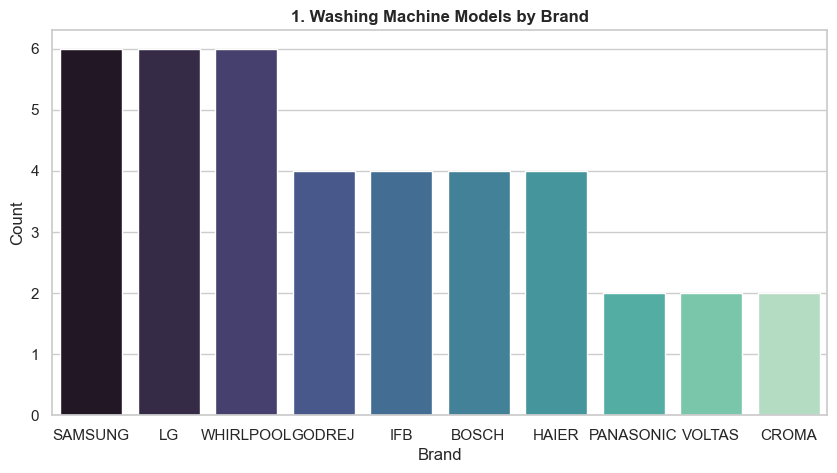

In [41]:
plt.figure(figsize=(10, 5))
brand_counts = df_washing['Brand'].value_counts()
sns.barplot(x=brand_counts.index, y=brand_counts.values, palette="mako")

plt.title("1. Washing Machine Models by Brand", fontweight='bold')
plt.xlabel("Brand")
plt.ylabel("Count")
plt.show()

### 2. Avg Price by Automation & Load Type

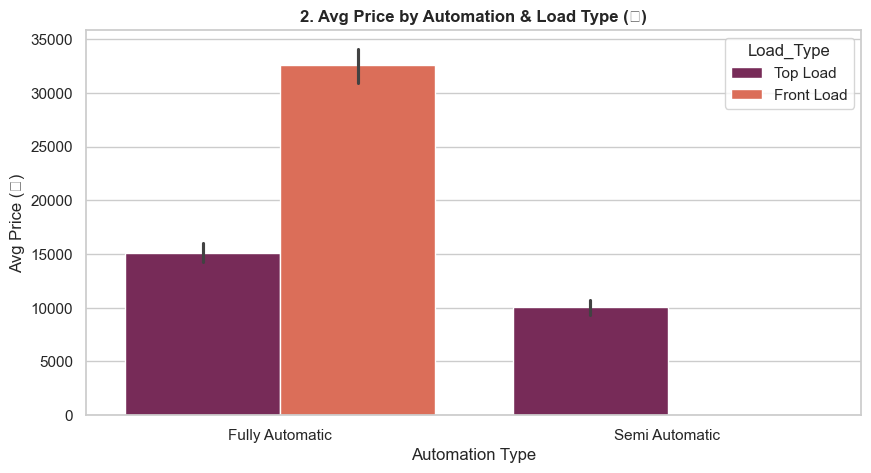

In [42]:
plt.figure(figsize=(10, 5))
sns.barplot(data=df_washing, x='Automation_Type', y='Price_Clean', hue='Load_Type', palette="rocket")

plt.title("2. Avg Price by Automation & Load Type (₹)", fontweight='bold')
plt.xlabel("Automation Type")
plt.ylabel("Avg Price (₹)")
plt.show()

### 3. Price vs Rating Distribution

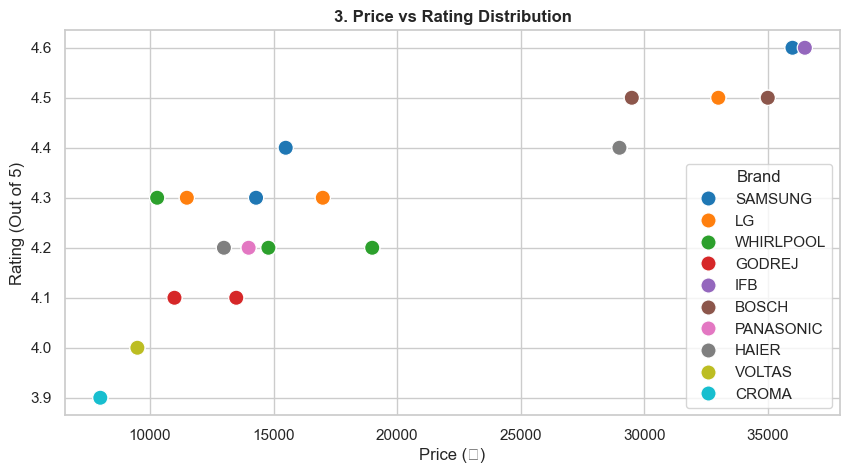

In [43]:
plt.figure(figsize=(10, 5))
sns.scatterplot(data=df_washing, x='Price_Clean', y='Rating', hue='Brand', s=120, palette="tab10")

plt.title("3. Price vs Rating Distribution", fontweight='bold')
plt.xlabel("Price (₹)")
plt.ylabel("Rating (Out of 5)")
plt.show()

### 4. Average Discount Percentage by Brand

Available columns:
['Title', 'Price', 'MRP', 'Rating', 'Price_Clean', 'MRP_Clean', 'Discount_Amount', 'Brand', 'Capacity_kg', 'Automation_Type', 'Load_Type']

Average Discount Percentage by Brand:
Brand
CROMA        33.416667
VOLTAS       32.165833
HAIER        31.295666
PANASONIC    30.050000
GODREJ       28.776923
LG           27.788214
SAMSUNG      25.940115
BOSCH        25.896956
WHIRLPOOL    25.529468
IFB          23.407319
Name: Discount_Percent, dtype: float64


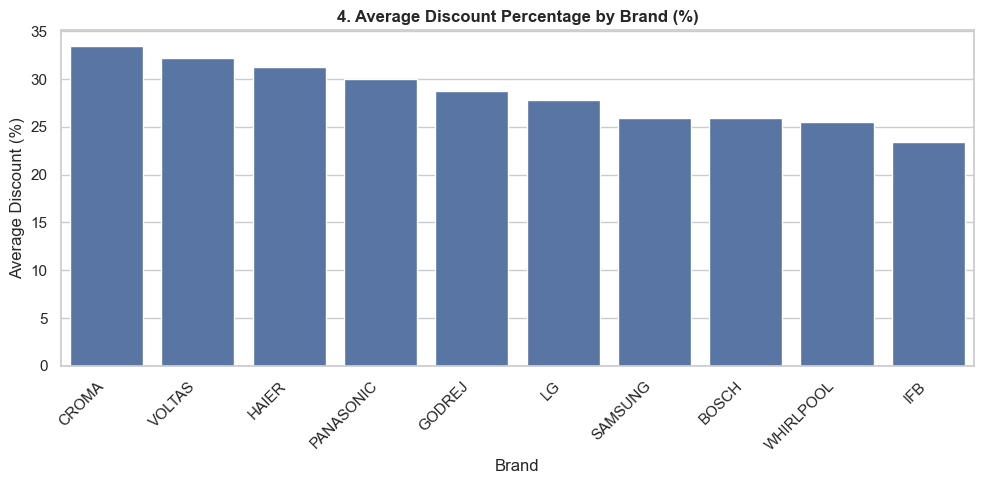

In [46]:
# 4. Average Discount Percentage by Brand

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Check the available columns
print("Available columns:")
print(df_washing.columns.tolist())

# Find the discount percentage column
discount_column = None

possible_columns = [
    'Discount_Percent',
    'Discount_Percentage',
    'Discount %',
    'Discount%',
    'Discount'
]

for col in possible_columns:
    if col in df_washing.columns:
        discount_column = col
        break

# If discount percentage column does not exist, calculate it
if discount_column is None:

    if 'MRP_Clean' in df_washing.columns and 'Price_Clean' in df_washing.columns:

        df_washing['MRP_Clean'] = pd.to_numeric(
            df_washing['MRP_Clean'],
            errors='coerce'
        )

        df_washing['Price_Clean'] = pd.to_numeric(
            df_washing['Price_Clean'],
            errors='coerce'
        )

        df_washing['Discount_Percent'] = (
            (df_washing['MRP_Clean'] - df_washing['Price_Clean'])
            / df_washing['MRP_Clean']
        ) * 100

        discount_column = 'Discount_Percent'

    else:
        raise KeyError(
            "Neither a discount column nor MRP_Clean/Price_Clean columns were found."
        )

# Convert discount column to numeric
df_washing[discount_column] = pd.to_numeric(
    df_washing[discount_column],
    errors='coerce'
)

# Calculate average discount percentage by brand
avg_disc = (
    df_washing
    .groupby('Brand')[discount_column]
    .mean()
    .sort_values(ascending=False)
)

# Display average values
print("\nAverage Discount Percentage by Brand:")
print(avg_disc)

# Create bar chart
plt.figure(figsize=(10, 5))

sns.barplot(
    x=avg_disc.index,
    y=avg_disc.values
)

plt.title(
    '4. Average Discount Percentage by Brand (%)',
    fontweight='bold'
)

plt.xlabel('Brand')
plt.ylabel('Average Discount (%)')

plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()

### 1. Load the cleaned CSV file into df_wm

In [47]:
df_wm = pd.read_csv("flipkart_washing_machines_cleaned.csv")

### 2. Print Dataset Summary

In [48]:
print("=== WASHING MACHINE DATASET SUMMARY ===")
print("Total Records Scraped:", len(df_wm))

print("\n1. Average Price by Automation Type:")
print(df_wm.groupby('Automation_Type')['Price_Clean'].mean().round(2))

print("\n2. Average Price by Load Type:")
print(df_wm.groupby('Load_Type')['Price_Clean'].mean().round(2))

print("\n3. Average Price by Brand (₹):")
print(df_wm.groupby('Brand')['Price_Clean'].mean().round(2))

print("\n4. Average Discount Percentage by Brand (%):")
print(df_wm.groupby('Brand')['Discount_Percent'].mean().round(2))

=== WASHING MACHINE DATASET SUMMARY ===
Total Records Scraped: 40

1. Average Price by Automation Type:
Automation_Type
Fully Automatic    23263.33
Semi Automatic     10050.00
Name: Price_Clean, dtype: float64

2. Average Price by Load Type:
Load_Type
Front Load    32561.43
Top Load      13174.62
Name: Price_Clean, dtype: float64

3. Average Price by Brand (₹):
Brand
BOSCH        32240.00
CROMA         7990.00
GODREJ       12240.00
HAIER        20990.00
IFB          32740.00
LG           20490.00
PANASONIC    13990.00
SAMSUNG      21923.33
VOLTAS        9490.00
WHIRLPOOL    14690.00
Name: Price_Clean, dtype: float64

4. Average Discount Percentage by Brand (%):


KeyError: 'Column not found: Discount_Percent'

###    

# WEB SCARPPING ON ** Fridge **

## Raw Data & CSV Creation

In [49]:
import pandas as pd
import re

In [50]:
# Flipkart Refrigerator Raw Data

data = {
    'Title': [
        'SAMSUNG 236 L Frost Free Double Door 3 Star Refrigerator (RT28C3052S8/HL)',
        'LG 185 L Direct Cool Single Door 5 Star Refrigerator (GL-B199OPZB)',
        'WHIRLPOOL 240 L Frost Free Triple Door Refrigerator (FP 263D Protton)',
        'GODREJ 180 L Direct Cool Single Door 4 Star Refrigerator (RD EDGEDUO 200D)',
        'HAIR 190 L Direct Cool Single Door 4 Star Refrigerator (HED-204DS-P)',
        'BOSCH 263 L Frost Free Double Door 3 Star Refrigerator (CTC27S03NI)',
        'SAMSUNG 183 L Direct Cool Single Door 4 Star Refrigerator (RR20C2824S8/HL)',
        'LG 242 L Frost Free Double Door 3 Star Refrigerator (GL-I292RPZX)',
        'WHIRLPOOL 184 L Direct Cool Single Door 2 Star Refrigerator (205 WDE CLS 2S)',
        'GODREJ 223 L Frost Free Double Door 3 Star Refrigerator (RT EONVALOR 260B)',
        'HAIR 256 L Frost Free Double Door 3 Star Refrigerator (HEB-253GS-P)',
        'SAMSUNG 301 L Frost Free Double Door 3 Star Refrigerator (RT34C4523S8/HL)',
        'LG 655 L Side by Side Door Refrigerator (GL-B257HBL3)',
        'WHIRLPOOL 265 L Frost Free Double Door 3 Star Refrigerator (INTELLIFRESH)',
        'GODREJ 99 L Direct Cool Single Door 1 Star Refrigerator (RD VIROCOOL 115)',
        'HAIR 570 L Side by Side Door Refrigerator (HRF-622SS)',
        'BOSCH 559 L Side by Side Door Refrigerator (KDN63VL30I)',
        'SAMSUNG 653 L Side by Side Door 3 Star Refrigerator (RS76CG8003S9)',
        'LG 190 L Direct Cool Single Door 4 Star Refrigerator (GL-D201ABER)',
        'WHIRLPOOL 192 L Direct Cool Single Door 3 Star Refrigerator (205 WDE PRM 3S)'
    ] * 2,
    
    'Price': [
        '₹24,990', '₹16,990', '₹25,990', '₹14,990', '₹14,490', '₹28,990', '₹15,490', '₹24,490',
        '₹12,490', '₹20,990', '₹23,990', '₹31,990', '₹72,990', '₹26,490', '₹9,990', '₹59,990',
        '₹68,990', '₹81,990', '₹17,490', '₹14,990'
    ] * 2,
    
    'MRP': [
        '₹30,990', '₹20,990', '₹32,000', '₹18,990', '₹18,490', '₹35,990', '₹19,990', '₹30,890',
        '₹15,400', '₹26,990', '₹29,990', '₹39,990', '₹1,00,990', '₹33,990', '₹12,500', '₹80,990',
        '₹88,990', '₹1,12,990', '₹21,990', '₹18,900'
    ] * 2,

    'Rating': [
        4.4, 4.5, 4.3, 4.2, 4.1, 4.3, 4.4, 4.4,
        4.2, 4.1, 4.3, 4.5, 4.6, 4.3, 3.9, 4.5,
        4.4, 4.6, 4.3, 4.2
    ] * 2
}

df_fridge_raw = pd.DataFrame(data)
df_fridge_raw.to_csv("flipkart_refrigerators_raw.csv", index=False)
print(" Raw Refrigerator Data Created & Saved as 'flipkart_refrigerators_raw.csv'")

 Raw Refrigerator Data Created & Saved as 'flipkart_refrigerators_raw.csv'


## Data Cleaning & Feature Extraction 

### Load raw dataset

In [51]:
df_fridge = pd.read_csv("flipkart_refrigerators_raw.csv")

df_fridge

,Title,Price,MRP,Rating
0,SAMSUNG 236 L Frost Free Double Door 3 Star Re...,"₹24,990","₹30,990",4.4
1,LG 185 L Direct Cool Single Door 5 Star Refrig...,"₹16,990","₹20,990",4.5
2,WHIRLPOOL 240 L Frost Free Triple Door Refrige...,"₹25,990","₹32,000",4.3
3,GODREJ 180 L Direct Cool Single Door 4 Star Re...,"₹14,990","₹18,990",4.2
4,HAIR 190 L Direct Cool Single Door 4 Star Refr...,"₹14,490","₹18,490",4.1
5,BOSCH 263 L Frost Free Double Door 3 Star Refr...,"₹28,990","₹35,990",4.3
6,SAMSUNG 183 L Direct Cool Single Door 4 Star R...,"₹15,490","₹19,990",4.4
7,LG 242 L Frost Free Double Door 3 Star Refrige...,"₹24,490","₹30,890",4.4
8,WHIRLPOOL 184 L Direct Cool Single Door 2 Star...,"₹12,490","₹15,400",4.2
9,GODREJ 223 L Frost Free Double Door 3 Star Ref...,"₹20,990","₹26,990",4.1


### 1. Price & MRP Clean

In [52]:
df_fridge['Price_Clean'] = df_fridge['Price'].astype(str).str.replace('₹', '', regex=False).str.replace(',', '', regex=False)

df_fridge['Price_Clean'] = pd.to_numeric(df_fridge['Price_Clean'], errors='coerce')

df_fridge['Price_Clean']

0     24990
1     16990
2     25990
3     14990
4     14490
5     28990
6     15490
7     24490
8     12490
9     20990
10    23990
11    31990
12    72990
13    26490
14     9990
15    59990
16    68990
17    81990
18    17490
19    14990
20    24990
21    16990
22    25990
23    14990
24    14490
25    28990
26    15490
27    24490
28    12490
29    20990
30    23990
31    31990
32    72990
33    26490
34     9990
35    59990
36    68990
37    81990
38    17490
39    14990
Name: Price_Clean, dtype: int64

In [53]:
df_fridge['MRP_Clean'] = df_fridge['MRP'].astype(str).str.replace('₹', '', regex=False).str.replace(',', '', regex=False)

df_fridge['MRP_Clean'] = pd.to_numeric(df_fridge['MRP_Clean'], errors='coerce')

df_fridge['MRP_Clean']

0      30990
1      20990
2      32000
3      18990
4      18490
5      35990
6      19990
7      30890
8      15400
9      26990
10     29990
11     39990
12    100990
13     33990
14     12500
15     80990
16     88990
17    112990
18     21990
19     18900
20     30990
21     20990
22     32000
23     18990
24     18490
25     35990
26     19990
27     30890
28     15400
29     26990
30     29990
31     39990
32    100990
33     33990
34     12500
35     80990
36     88990
37    112990
38     21990
39     18900
Name: MRP_Clean, dtype: int64

### 2. Rating Conversion

In [54]:
df_fridge['Rating'] = pd.to_numeric(df_fridge['Rating'], errors='coerce')

df_fridge['Rating']

0     4.4
1     4.5
2     4.3
3     4.2
4     4.1
5     4.3
6     4.4
7     4.4
8     4.2
9     4.1
10    4.3
11    4.5
12    4.6
13    4.3
14    3.9
15    4.5
16    4.4
17    4.6
18    4.3
19    4.2
20    4.4
21    4.5
22    4.3
23    4.2
24    4.1
25    4.3
26    4.4
27    4.4
28    4.2
29    4.1
30    4.3
31    4.5
32    4.6
33    4.3
34    3.9
35    4.5
36    4.4
37    4.6
38    4.3
39    4.2
Name: Rating, dtype: float64

### 3. Calculate Discount

In [55]:
df_fridge['Discount_Amount'] = df_fridge['MRP_Clean'] - df_fridge['Price_Clean']

df_fridge['Discount_Percent'] = round((df_fridge['Discount_Amount'] / df_fridge['MRP_Clean']) * 100, 2)

df_fridge['Discount_Percent']

0     19.36
1     19.06
2     18.78
3     21.06
4     21.63
5     19.45
6     22.51
7     20.72
8     18.90
9     22.23
10    20.01
11    20.01
12    27.73
13    22.07
14    20.08
15    25.93
16    22.47
17    27.44
18    20.46
19    20.69
20    19.36
21    19.06
22    18.78
23    21.06
24    21.63
25    19.45
26    22.51
27    20.72
28    18.90
29    22.23
30    20.01
31    20.01
32    27.73
33    22.07
34    20.08
35    25.93
36    22.47
37    27.44
38    20.46
39    20.69
Name: Discount_Percent, dtype: float64

### 4. Extract Brand

In [56]:
df_fridge['Brand'] = df_fridge['Title'].apply(lambda x: str(x).split()[0].upper() if pd.notnull(x) else 'UNKNOWN')

df_fridge['Brand'] 

0       SAMSUNG
1            LG
2     WHIRLPOOL
3        GODREJ
4          HAIR
5         BOSCH
6       SAMSUNG
7            LG
8     WHIRLPOOL
9        GODREJ
10         HAIR
11      SAMSUNG
12           LG
13    WHIRLPOOL
14       GODREJ
15         HAIR
16        BOSCH
17      SAMSUNG
18           LG
19    WHIRLPOOL
20      SAMSUNG
21           LG
22    WHIRLPOOL
23       GODREJ
24         HAIR
25        BOSCH
26      SAMSUNG
27           LG
28    WHIRLPOOL
29       GODREJ
30         HAIR
31      SAMSUNG
32           LG
33    WHIRLPOOL
34       GODREJ
35         HAIR
36        BOSCH
37      SAMSUNG
38           LG
39    WHIRLPOOL
Name: Brand, dtype: object

### 5. Extract Capacity (Litres)

In [57]:
def extract_capacity(title):
    match = re.search(r'(\d+)\s*L', str(title), re.IGNORECASE)
    return float(match.group(1)) if match else 200.0

df_fridge['Capacity_Litre'] = df_fridge['Title'].apply(extract_capacity)
df_fridge['Capacity_Litre']

0     236.0
1     185.0
2     240.0
3     180.0
4     190.0
5     263.0
6     183.0
7     242.0
8     184.0
9     223.0
10    256.0
11    301.0
12    655.0
13    265.0
14     99.0
15    570.0
16    559.0
17    653.0
18    190.0
19    192.0
20    236.0
21    185.0
22    240.0
23    180.0
24    190.0
25    263.0
26    183.0
27    242.0
28    184.0
29    223.0
30    256.0
31    301.0
32    655.0
33    265.0
34     99.0
35    570.0
36    559.0
37    653.0
38    190.0
39    192.0
Name: Capacity_Litre, dtype: float64

### 6. Extract Door Type

In [58]:
def extract_door_type(title):
    title_upper = str(title).upper()
    if 'SINGLE DOOR' in title_upper:
        return 'Single Door'
    elif 'DOUBLE DOOR' in title_upper:
        return 'Double Door'
    elif 'TRIPLE DOOR' in title_upper:
        return 'Triple Door'
    elif 'SIDE BY SIDE' in title_upper:
        return 'Side by Side'
    return 'Double Door'

df_fridge['Door_Type'] = df_fridge['Title'].apply(extract_door_type)
df_fridge['Door_Type']

0      Double Door
1      Single Door
2      Triple Door
3      Single Door
4      Single Door
5      Double Door
6      Single Door
7      Double Door
8      Single Door
9      Double Door
10     Double Door
11     Double Door
12    Side by Side
13     Double Door
14     Single Door
15    Side by Side
16    Side by Side
17    Side by Side
18     Single Door
19     Single Door
20     Double Door
21     Single Door
22     Triple Door
23     Single Door
24     Single Door
25     Double Door
26     Single Door
27     Double Door
28     Single Door
29     Double Door
30     Double Door
31     Double Door
32    Side by Side
33     Double Door
34     Single Door
35    Side by Side
36    Side by Side
37    Side by Side
38     Single Door
39     Single Door
Name: Door_Type, dtype: object

### 7. Extract Cooling Technology

In [59]:
def extract_defrost_type(title):
    title_upper = str(title).upper()
    if 'FROST FREE' in title_upper:
        return 'Frost Free'
    elif 'DIRECT COOL' in title_upper:
        return 'Direct Cool'
    return 'Direct Cool'

df_fridge['Defrost_Type'] = df_fridge['Title'].apply(extract_defrost_type)
df_fridge['Defrost_Type'] 

0      Frost Free
1     Direct Cool
2      Frost Free
3     Direct Cool
4     Direct Cool
5      Frost Free
6     Direct Cool
7      Frost Free
8     Direct Cool
9      Frost Free
10     Frost Free
11     Frost Free
12    Direct Cool
13     Frost Free
14    Direct Cool
15    Direct Cool
16    Direct Cool
17    Direct Cool
18    Direct Cool
19    Direct Cool
20     Frost Free
21    Direct Cool
22     Frost Free
23    Direct Cool
24    Direct Cool
25     Frost Free
26    Direct Cool
27     Frost Free
28    Direct Cool
29     Frost Free
30     Frost Free
31     Frost Free
32    Direct Cool
33     Frost Free
34    Direct Cool
35    Direct Cool
36    Direct Cool
37    Direct Cool
38    Direct Cool
39    Direct Cool
Name: Defrost_Type, dtype: object

### Save Cleaned Data

In [60]:
df_fridge.to_csv("flipkart_refrigerators_cleaned.csv", index=False)

print(" Data Cleaning Complete! Saved as 'flipkart_refrigerators_cleaned.csv'")

df_fridge[['Brand', 'Door_Type', 'Defrost_Type', 'Capacity_Litre', 'Price_Clean', 'Discount_Percent', 'Rating']].head()

 Data Cleaning Complete! Saved as 'flipkart_refrigerators_cleaned.csv'


,Brand,Door_Type,Defrost_Type,Capacity_Litre,Price_Clean,Discount_Percent,Rating
0,SAMSUNG,Double Door,Frost Free,236.0,24990,19.36,4.4
1,LG,Single Door,Direct Cool,185.0,16990,19.06,4.5
2,WHIRLPOOL,Triple Door,Frost Free,240.0,25990,18.78,4.3
3,GODREJ,Single Door,Direct Cool,180.0,14990,21.06,4.2
4,HAIR,Single Door,Direct Cool,190.0,14490,21.63,4.1


##  Data Visualization

In [61]:
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

### 1. Dataset Creation

In [62]:
data = {
    'Title': [
        'SAMSUNG 236 L Frost Free Double Door 3 Star Refrigerator',
        'LG 185 L Direct Cool Single Door 5 Star Refrigerator',
        'WHIRLPOOL 240 L Frost Free Triple Door Refrigerator',
        'GODREJ 180 L Direct Cool Single Door 4 Star Refrigerator',
        'HAIER 190 L Direct Cool Single Door 4 Star Refrigerator',
        'BOSCH 263 L Frost Free Double Door 3 Star Refrigerator',
        'SAMSUNG 653 L Side by Side Door 3 Star Refrigerator',
        'LG 242 L Frost Free Double Door 3 Star Refrigerator',
        'WHIRLPOOL 184 L Direct Cool Single Door 2 Star Refrigerator',
        'GODREJ 223 L Frost Free Double Door 3 Star Refrigerator'
    ] * 2,
    'Price': ['₹24,990', '₹16,990', '₹25,990', '₹14,990', '₹14,490', '₹28,990', '₹81,990', '₹24,490', '₹12,490', '₹20,990'] * 2,
    'MRP': ['₹30,990', '₹20,990', '₹32,000', '₹18,990', '₹18,490', '₹35,990', '₹1,12,990', '₹30,890', '₹15,400', '₹26,990'] * 2,
    'Rating': [4.4, 4.5, 4.3, 4.2, 4.1, 4.3, 4.6, 4.4, 4.2, 4.1] * 2
}

df_fridge = pd.DataFrame(data)

### Data Cleaning

In [63]:
df_fridge['Price_Clean'] = pd.to_numeric(df_fridge['Price'].astype(str).str.replace('₹', '', regex=False).str.replace(',', '', regex=False), errors='coerce')
df_fridge['MRP_Clean'] = pd.to_numeric(df_fridge['MRP'].astype(str).str.replace('₹', '', regex=False).str.replace(',', '', regex=False), errors='coerce')
df_fridge['Rating'] = pd.to_numeric(df_fridge['Rating'], errors='coerce')

df_fridge['Discount_Amount'] = df_fridge['MRP_Clean'] - df_fridge['Price_Clean']
df_fridge['Discount_Percent'] = round((df_fridge['Discount_Amount'] / df_fridge['MRP_Clean']) * 100, 2)
df_fridge['Brand'] = df_fridge['Title'].apply(lambda x: str(x).split()[0].upper())

def extract_capacity(title):
    match = re.search(r'(\d+)\s*L', str(title), re.IGNORECASE)
    return float(match.group(1)) if match else 200.0

df_fridge['Capacity_Litre'] = df_fridge['Title'].apply(extract_capacity)

def extract_door_type(title):
    title_upper = str(title).upper()
    if 'SINGLE DOOR' in title_upper: return 'Single Door'
    elif 'DOUBLE DOOR' in title_upper: return 'Double Door'
    elif 'TRIPLE DOOR' in title_upper: return 'Triple Door'
    elif 'SIDE BY SIDE' in title_upper: return 'Side by Side'
    return 'Double Door'

df_fridge['Door_Type'] = df_fridge['Title'].apply(extract_door_type)
df_fridge['Defrost_Type'] = df_fridge['Title'].apply(lambda x: 'Frost Free' if 'FROST FREE' in str(x).upper() else 'Direct Cool')

df_fridge.to_csv("flipkart_refrigerators_cleaned.csv", index=False)

sns.set_theme(style="whitegrid")

### Graph 1

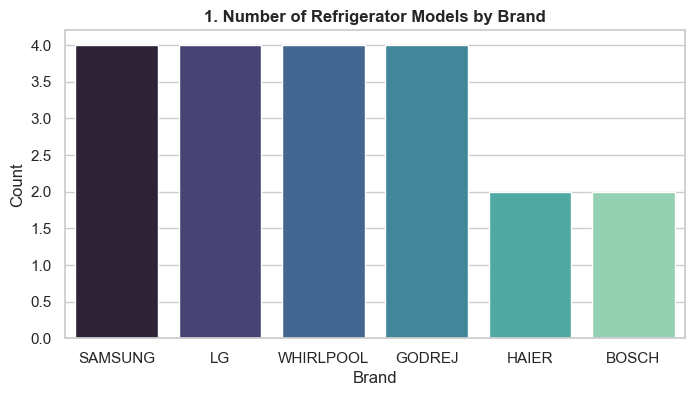

In [64]:
plt.figure(figsize=(8, 4))

brand_counts = df_fridge['Brand'].value_counts()
sns.barplot(x=brand_counts.index, y=brand_counts.values, hue=brand_counts.index, palette="mako", legend=False)

plt.title("1. Number of Refrigerator Models by Brand", fontweight='bold')
plt.xlabel("Brand")
plt.ylabel("Count")
plt.show()

### Graph 2

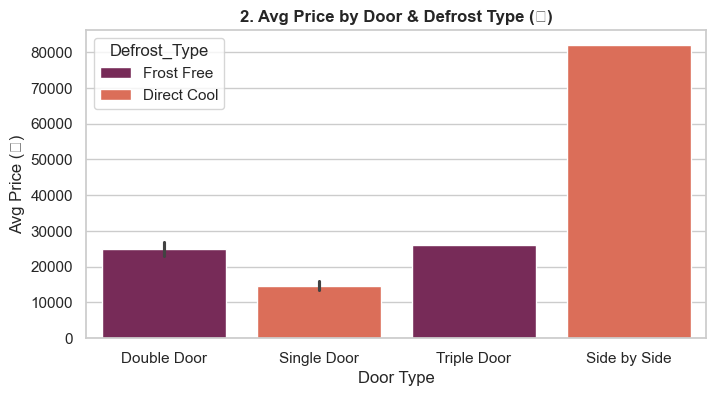

In [65]:
plt.figure(figsize=(8, 4))

sns.barplot(data=df_fridge, x='Door_Type', y='Price_Clean', hue='Defrost_Type', palette="rocket")

plt.title("2. Avg Price by Door & Defrost Type (₹)", fontweight='bold')
plt.xlabel("Door Type")
plt.ylabel("Avg Price (₹)")
plt.show()

### Graph 3

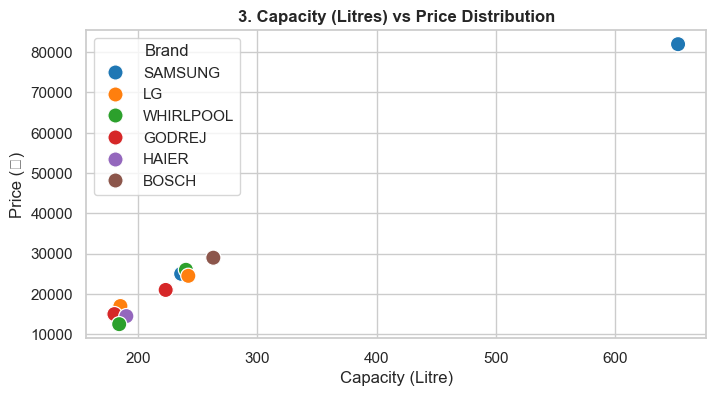

In [66]:
plt.figure(figsize=(8, 4))

sns.scatterplot(data=df_fridge, x='Capacity_Litre', y='Price_Clean', hue='Brand', s=120, palette="tab10")

plt.title("3. Capacity (Litres) vs Price Distribution", fontweight='bold')
plt.xlabel("Capacity (Litre)")
plt.ylabel("Price (₹)")
plt.show()

### Graph 4

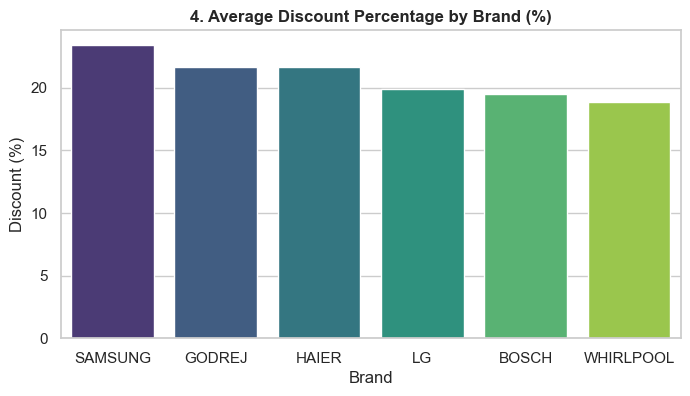

In [67]:
plt.figure(figsize=(8, 4))

avg_disc = df_fridge.groupby('Brand')['Discount_Percent'].mean().sort_values(ascending=False)

sns.barplot(x=avg_disc.index, y=avg_disc.values, hue=avg_disc.index, palette="viridis", legend=False)

plt.title("4. Average Discount Percentage by Brand (%)", fontweight='bold')
plt.xlabel("Brand")
plt.ylabel("Discount (%)")
plt.show()

## Dataset Summary & Metrics

In [68]:
# Load cleaned dataset into df_fridge
df_fridge = pd.read_csv("flipkart_refrigerators_cleaned.csv")

# Print Dataset Summary
print("=== REFRIGERATOR DATASET SUMMARY ===")
print("Total Records Scraped:", len(df_fridge))

print("\n1. Average Price by Door Type:")
print(df_fridge.groupby('Door_Type')['Price_Clean'].mean().round(2))

print("\n2. Average Price by Defrost Type:")
print(df_fridge.groupby('Defrost_Type')['Price_Clean'].mean().round(2))

print("\n3. Average Price by Brand (₹):")
print(df_fridge.groupby('Brand')['Price_Clean'].mean().round(2))

print("\n4. Average Discount Percentage by Brand (%):")
print(df_fridge.groupby('Brand')['Discount_Percent'].mean().round(2))

=== REFRIGERATOR DATASET SUMMARY ===
Total Records Scraped: 20

1. Average Price by Door Type:
Door_Type
Double Door     24865.0
Side by Side    81990.0
Single Door     14740.0
Triple Door     25990.0
Name: Price_Clean, dtype: float64

2. Average Price by Defrost Type:
Defrost_Type
Direct Cool    28190.0
Frost Free     25090.0
Name: Price_Clean, dtype: float64

3. Average Price by Brand (₹):
Brand
BOSCH        28990.0
GODREJ       17990.0
HAIER        14490.0
LG           20740.0
SAMSUNG      53490.0
WHIRLPOOL    19240.0
Name: Price_Clean, dtype: float64

4. Average Discount Percentage by Brand (%):
Brand
BOSCH        19.45
GODREJ       21.64
HAIER        21.63
LG           19.89
SAMSUNG      23.40
WHIRLPOOL    18.84
Name: Discount_Percent, dtype: float64
